In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Evaluating Model Performance against Stockfish
Let's evaluate the trained model's performance by playing several games against Stockfish and tallying the results.

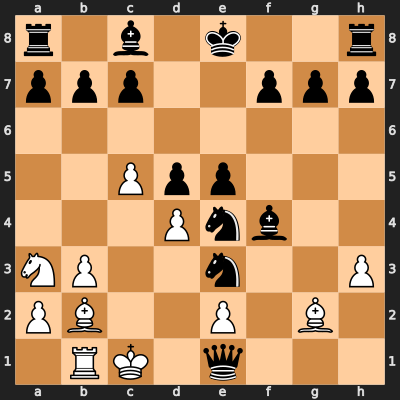

In [ ]:
# --- INSTALL DEPENDENCIES ---
import sys
import subprocess

def install_packages():
    subprocess.check_call([sys.executable, "-m", "pip", "install", "chess", "torch", "numpy"])
    # Install Stockfish for Linux (Colab environment)
    print("Updating apt-get and installing Stockfish...")

    # Update package list
    update_result = subprocess.run(["sudo", "apt-get", "update"], capture_output=True, text=True)
    if update_result.returncode != 0:
        print(f"apt-get update failed: {update_result.stderr}")
    else:
        print("apt-get update successful.")

    # Install Stockfish
    install_result = subprocess.run(["sudo", "apt-get", "install", "stockfish", "-y"], capture_output=True, text=True) # Added -y for non-interactive
    if install_result.returncode != 0:
        print(f"Stockfish installation failed: {install_result.stderr}")
        print(f"Stdout: {install_result.stdout}")
        print(f"Stderr: {install_result.stderr}")
    else:
        print("Stockfish installation successful.")
        # Verify installation using the full path
        try:
            subprocess.run(["/usr/games/stockfish", "uci"], capture_output=True, text=True, check=True)
            print("Stockfish verified to be working at /usr/games/stockfish.")
        except subprocess.CalledProcessError:
            print("Stockfish is installed but not found in PATH or not working as expected.")
        except FileNotFoundError:
            print("Stockfish executable not found at /usr/games/stockfish. There might be an issue with the installation.")

install_packages()

# --- IMPORTS ---
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import chess
import chess.svg
import chess.engine
import numpy as np
import time
import random
from collections import deque
from IPython.display import display, clear_output, HTML, SVG

# --- CONFIGURATION ---
class Config:
    def __init__(self):
        self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        self.num_res_blocks = 12      # Bumped up for more complexity
        self.num_channels = 64
        self.mcts_sims = 150         # Bumped up for more simulations during training
        self.c_puct = 1.0            # Exploration constant
        self.lr = 0.001
        self.batch_size = 32
        self.buffer_size = 3000      # Bumped up for more games to remember
        self.epochs = 7              # More training epochs
        self.num_selfplay_games = 6
        self.stockfish_skill_level = 0 # Stockfish skill level (0-20)

CFG = Config()
print(f"Running on: {CFG.device}")

# --- NEURAL NETWORK (ResNet) ---
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):
        residual = x
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.bn2(self.conv2(x))
        x += residual
        return F.relu(x)

class AlphaZeroNet(nn.Module):
    def __init__(self):
        super().__init__()
        # Input: 12 planes (6 piece types * 2 colors)
        self.start_conv = nn.Conv2d(12, CFG.num_channels, 3, padding=1)
        self.bn_start = nn.BatchNorm2d(CFG.num_channels)

        # Residual Tower
        self.res_blocks = nn.ModuleList([ResidualBlock(CFG.num_channels) for _ in range(CFG.num_res_blocks)])

        # Policy Head (Output: 4096 potential moves [64 from * 64 to])
        self.p_conv = nn.Conv2d(CFG.num_channels, 4, 1) # Reduce depth
        self.p_bn = nn.BatchNorm2d(4)
        self.p_fc = nn.Linear(4 * 8 * 8, 4096)

        # Value Head (Output: 1 scalar [-1, 1])
        self.v_conv = nn.Conv2d(CFG.num_channels, 2, 1)
        self.v_bn = nn.BatchNorm2d(2)
        self.v_fc1 = nn.Linear(2 * 8 * 8, 32)
        self.v_fc2 = nn.Linear(32, 1)

    def forward(self, x):
        x = F.relu(self.bn_start(self.start_conv(x)))
        for block in self.res_blocks:
            x = block(x)

        # Policy
        p = F.relu(self.p_bn(self.p_conv(x)))
        p = p.view(-1, 4 * 8 * 8)
        p = self.p_fc(p)
        # Note: We don't softmax here, we do it after masking illegal moves

        # Value
        v = F.relu(self.v_bn(self.v_conv(x)))
        v = v.view(-1, 2 * 8 * 8)
        v = F.relu(self.v_fc1(v))
        v = torch.tanh(self.v_fc2(v))

        return p, v

# --- HELPERS ---
def board_to_tensor(board):
    # Convert board to 12x8x8 tensor
    # Layers 0-5: White P, N, B, R, Q, K
    # Layers 6-11: Black P, N, B, R, Q, K
    state = np.zeros((12, 8, 8), dtype=np.float32)

    for sq, piece in board.piece_map().items():
        layer = piece.piece_type - 1
        if piece.color == chess.BLACK:
            layer += 6
        row, col = divmod(sq, 8)
        state[layer, 7-row, col] = 1.0 # 7-row to flip for standard matrix view

    return torch.tensor(state).unsqueeze(0).to(CFG.device)

def encode_move(move):
    # Simple encoding: from_sq * 64 + to_sq
    return move.from_square * 64 + move.to_square

def decode_move(idx):
    f, t = divmod(idx, 64)
    return chess.Move(f, t)

# --- MCTS ENGINE ---
class MCTSNode:
    def __init__(self, parent=None, prior=0):
        self.parent = parent
        self.children = {}
        self.visits = 0
        self.value_sum = 0
        self.prior = prior # Probability from NN

    def value(self):
        if self.visits == 0: return 0
        return self.value_sum / self.visits

    def ucb(self, parent_visits):
        # Upper Confidence Bound for Trees (PUCT)
        if self.visits == 0:
            q_val = 0
        else:
            q_val = -self.value_sum / self.visits # Perspective flip

        u_val = CFG.c_puct * self.prior * np.sqrt(parent_visits) / (1 + self.visits)
        return q_val + u_val

class MCTS:
    def __init__(self, model, mcts_sims=None):
        self.model = model
        self.mcts_sims = mcts_sims if mcts_sims is not None else CFG.mcts_sims

    def search(self, board):
        root = MCTSNode()

        for _ in range(self.mcts_sims):
            node = root
            sim_board = board.copy()

            # 1. Selection
            while node.children:
                best_move, node = max(node.children.items(), key=lambda item: item[1].ucb(node.visits))
                sim_board.push(best_move)

            # 2. Expansion & Evaluation
            if not sim_board.is_game_over():
                state_tensor = board_to_tensor(sim_board)
                self.model.eval()
                with torch.no_grad():
                    policy_logits, value = self.model(state_tensor)

                # Mask illegal moves
                policy_probs = F.softmax(policy_logits, dim=1).cpu().numpy()[0]
                legal_moves = list(sim_board.legal_moves)

                sum_probs = 0
                for move in legal_moves:
                    idx = encode_move(move)
                    prob = policy_probs[idx]
                    node.children[move] = MCTSNode(node, prior=prob)
                    sum_probs += prob

                # Normalize priors
                if sum_probs > 0:
                    for child in node.children.values():
                        child.prior /= sum_probs

                val = value.item()
            else:
                # Terminal state
                if sim_board.result() == "1-0": val = 1
                elif sim_board.result() == "0-1": val = -1
                else: val = 0

                # Fix perspective (if it's black's turn to move in sim_board,
                # a positive val means white won, which is bad for black)
                if sim_board.turn == chess.BLACK:
                    val = -val

            # 3. Backpropagation
            while node:
                node.visits += 1
                node.value_sum += val
                val = -val # Flip perspective for opponent
                node = node.parent

        # Select move based on visit counts (temperature=1 usually)
        if not root.children:
            return random.choice(list(board.legal_moves)) # Fallback

        moves = list(root.children.keys())
        visits = [root.children[m].visits for m in moves]

        # Softmax based on visits
        total_visits = sum(visits)
        probs = [v / total_visits for v in visits]

        # Sample move
        chosen_move = np.random.choice(moves, p=probs)
        return chosen_move

# --- TRAINING LOOP ---
def self_play(model, games=1, current_epoch=0):
    mcts = MCTS(model) # Uses CFG.mcts_sims
    data_buffer = [] # (state, policy_target, value_target)

    for g in range(games):
        board = chess.Board()
        game_history = []

        while not board.is_game_over():
            # Quick visual update
            if g == 0: # Only visualize first game of batch
                clear_output(wait=True)
                display(HTML(f"<h3>Epoch {current_epoch+1}/{CFG.epochs} - Self Play Training... (Game {g+1}/{games})</h3>"))
                display(SVG(chess.svg.board(board=board, size=300)))
                time.sleep(0.2) # Add a small delay

            # Run MCTS
            root = MCTSNode()
            # ... (Simplified MCTS call for training data generation) ...
            # We reuse the logic inside MCTS class but need to extract probs

            # --- Inline MCTS Logic for Data Extraction ---
            for _ in range(CFG.mcts_sims):
                node = root
                sim_board = board.copy()
                while node.children:
                    best_move, node = max(node.children.items(), key=lambda item: item[1].ucb(node.visits))
                    sim_board.push(best_move)

                if not sim_board.is_game_over():
                    st = board_to_tensor(sim_board)
                    model.eval()
                    with torch.no_grad(): p, v = model(st)
                    probs = F.softmax(p, dim=1).cpu().numpy()[0]
                    legal = list(sim_board.legal_moves)
                    current_probs = {}
                    for m in legal:
                        current_probs[m] = probs[encode_move(m)]

                    s_probs = sum(current_probs.values())
                    for m in legal:
                        node.children[m] = MCTSNode(node, prior=current_probs[m]/s_probs if s_probs else 0)
                    val = v.item()
                else:
                    res = sim_board.result()
                    val = 1 if res == "1-0" else -1 if res == "0-1" else 0
                    if sim_board.turn == chess.BLACK: val = -val

                while node:
                    node.visits += 1
                    node.value_sum += val
                    val = -val
                    node = node.parent
            # ---------------------------------------------

            # Generate Policy Target
            moves = list(root.children.keys())
            visits = [root.children[m].visits for m in moves]
            tot = sum(visits)
            pi = np.zeros(4096)
            for m, v in zip(moves, visits):
                pi[encode_move(m)] = v / tot

            # Store state
            game_history.append([board_to_tensor(board), pi, board.turn])

            # Pick move
            chosen_move = np.random.choice(moves, p=[v/tot for v in visits])
            board.push(chosen_move)

        # Game Over - Display final board and result for the current game
        if g == 0: # Only for the visualized game
            clear_output(wait=True)
            display(SVG(chess.svg.board(board=board, size=300)))
            display(HTML(f"<h3>Epoch {current_epoch+1}/{CFG.epochs} - Game {g+1}/{games} Over: {board.result()}</h3>"))

        # Assign Values for training data
        res = board.result()
        if res == "1-0": final_val = 1
        elif res == "0-1": final_val = -1
        else: final_val = 0

        for state, pi, turn in game_history:
            # If turn was White, they want 1. If Black, they want -1.
            # But the network always outputs value from *current player* perspective?
            # Simplified: AlphaZero value head is usually "outcome for current player"
            z = final_val if turn == chess.WHITE else -final_val
            data_buffer.append((state, torch.tensor(pi, dtype=torch.float32), torch.tensor([z], dtype=torch.float32)))

    return data_buffer

def train_step(model, optimizer, data):
    model.train()
    total_loss = 0

    # Simple batching
    indices = np.arange(len(data))
    np.random.shuffle(indices)

    for i in range(0, len(data), CFG.batch_size):
        batch_idx = indices[i:i+CFG.batch_size]
        if len(batch_idx) < 4: continue

        states = torch.cat([data[j][0] for j in batch_idx])
        pis = torch.stack([data[j][1] for j in batch_idx]).to(CFG.device)
        vs = torch.stack([data[j][2] for j in batch_idx]).to(CFG.device)

        pred_pi, pred_v = model(states)

        # Loss = (z - v)^2 - pi^T * log(p)
        loss_v = F.mse_loss(pred_v, vs)

        # Policy loss (Cross Entropy)
        # pred_pi is logits, use log_softmax
        log_probs = F.log_softmax(pred_pi, dim=1)
        loss_p = -torch.sum(pis * log_probs) / len(batch_idx)

        loss = loss_v + loss_p

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    return total_loss

# --- PLAY MODES ---
def play_vs_stockfish(model, mcts_sims=None):
    try:
        engine = chess.engine.SimpleEngine.popen_uci("/usr/games/stockfish")
        # Use 'setoption' instead of 'set_options' and check for its existence
        if hasattr(engine, 'setoption'):
            engine.setoption("Skill Level", CFG.stockfish_skill_level)
        else:
            print("Warning: Stockfish engine does not support 'setoption'. Skill level may not be set.")
    except Exception as e:
        print(f"Stockfish not found or error initializing: {e}")
        print("Please ensure Stockfish is installed by running the first cell.")
        return

    mcts = MCTS(model, mcts_sims=mcts_sims)
    board = chess.Board()

    while not board.is_game_over():
        clear_output(wait=True)
        display(SVG(chess.svg.board(board=board, size=400)))
        time.sleep(0.2) # Add a small delay

        if board.turn == chess.WHITE:
            print("AlphaZero Thinking...")
            move = mcts.search(board)
            board.push(move)
        else:
            print("Stockfish Thinking...")
            result = engine.play(board, chess.engine.Limit(time=0.1))
            board.push(result.move)

    clear_output(wait=True) # Clear current board and show final one
    display(SVG(chess.svg.board(board=board, size=400)))
    display(HTML(f"<h3>Game Over: {board.result()}</h3>"))
    engine.quit()

# --- MAIN EXECUTION ---
# 1. Init
net = AlphaZeroNet().to(CFG.device)
optimizer = optim.Adam(net.parameters(), lr=CFG.lr)
dataset = []

# 2. Training Loop
print("Starting Training Loop... (Press Stop to interrupt)")
try:
    for epoch in range(CFG.epochs):
        # A. Self Play
        new_data = self_play(net, games=CFG.num_selfplay_games, current_epoch=epoch) # Changed games from 4 to 6
        dataset.extend(new_data)
        if len(dataset) > CFG.buffer_size: dataset = dataset[-CFG.buffer_size:]

        # B. Train
        loss = train_step(net, optimizer, dataset)
        print(f"Epoch {epoch+1} Complete. Loss: {loss:.4f}. Buffer: {len(dataset)}")

except KeyboardInterrupt:
    print("Training stopped.")

# 3. Play
print("Training done. Launching match vs Stockfish...")
play_vs_stockfish(net)

In [6]:
def evaluate_model(model, num_games=5, mcts_sims=None):
    try:
        engine = chess.engine.SimpleEngine.popen_uci("/usr/games/stockfish")
        # Use 'setoption' instead of 'set_options' and check for its existence
        if hasattr(engine, 'setoption'):
            engine.setoption("Skill Level", CFG.stockfish_skill_level)
        else:
            print("Warning: Stockfish engine does not support 'setoption'. Skill level may not be set during evaluation.")
    except Exception as e:
        print(f"Stockfish not found or error initializing: {e}")
        print("Ensure Stockfish is installed and accessible.")
        return

    model_wins = 0
    stockfish_wins = 0
    draws = 0

    print(f"\n--- Starting {num_games} Evaluation Games against Stockfish ---")

    for i in range(num_games):
        board = chess.Board()
        mcts = MCTS(model, mcts_sims=mcts_sims)
        game_result = None

        # Alternate who plays white
        if i % 2 == 0:
            # Model (AlphaZero) plays White
            model_is_white = True
            print(f"Game {i+1}: AlphaZero (White) vs Stockfish (Black)")
        else:
            # Stockfish plays White
            model_is_white = False
            print(f"Game {i+1}: Stockfish (White) vs AlphaZero (Black)")

        while not board.is_game_over(claim_draw=True):
            if (board.turn == chess.WHITE and model_is_white) or \
               (board.turn == chess.BLACK and not model_is_white):
                # Model's turn
                # print("AlphaZero Thinking...") # Suppress verbose output for evaluation
                move = mcts.search(board)
                board.push(move)
            else:
                # Stockfish's turn
                # print("Stockfish Thinking...") # Suppress verbose output for evaluation
                result = engine.play(board, chess.engine.Limit(time=0.05)) # Short thinking time for speed
                board.push(result.move)

        # Determine result
        result_str = board.result()
        if result_str == "1-0": # White wins
            if model_is_white:
                model_wins += 1
                game_result = "AlphaZero Wins"
            else:
                stockfish_wins += 1
                game_result = "Stockfish Wins"
        elif result_str == "0-1": # Black wins
            if model_is_white:
                stockfish_wins += 1
                game_result = "Stockfish Wins"
            else:
                model_wins += 1
                game_result = "AlphaZero Wins"
        else:
            draws += 1
            game_result = "Draw"

        print(f"  Game {i+1} Finished: {game_result} - Result: {result_str}")

    engine.quit()

    print("\n--- Evaluation Summary ---")
    print(f"Total Games: {num_games}")
    print(f"AlphaZero Wins: {model_wins}")
    print(f"Stockfish Wins: {stockfish_wins}")
    print(f"Draws: {draws}")
    print(f"AlphaZero Win Rate: {model_wins/num_games * 100:.2f}%")

# Run the evaluation
evaluate_model(net, num_games=10, mcts_sims=200) # You can adjust the number of games and sims

RuntimeError: Error(s) in loading state_dict for AlphaZeroNet:
	Missing key(s) in state_dict: "start_conv.weight", "start_conv.bias", "bn_start.weight", "bn_start.bias", "bn_start.running_mean", "bn_start.running_var", "res_blocks.0.conv1.weight", "res_blocks.0.conv1.bias", "res_blocks.0.bn1.weight", "res_blocks.0.bn1.bias", "res_blocks.0.bn1.running_mean", "res_blocks.0.bn1.running_var", "res_blocks.0.conv2.weight", "res_blocks.0.conv2.bias", "res_blocks.0.bn2.weight", "res_blocks.0.bn2.bias", "res_blocks.0.bn2.running_mean", "res_blocks.0.bn2.running_var", "res_blocks.1.conv1.weight", "res_blocks.1.conv1.bias", "res_blocks.1.bn1.weight", "res_blocks.1.bn1.bias", "res_blocks.1.bn1.running_mean", "res_blocks.1.bn1.running_var", "res_blocks.1.conv2.weight", "res_blocks.1.conv2.bias", "res_blocks.1.bn2.weight", "res_blocks.1.bn2.bias", "res_blocks.1.bn2.running_mean", "res_blocks.1.bn2.running_var", "res_blocks.2.conv1.weight", "res_blocks.2.conv1.bias", "res_blocks.2.bn1.weight", "res_b

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# --- INSTALL DEPENDENCIES ---
import sys
import subprocess

def install_packages():
    subprocess.check_call([sys.executable, "-m", "pip", "install", "chess", "torch", "numpy", "numba"])
    # Install Stockfish for Linux (Colab environment)
    print("Updating apt-get and installing Stockfish...")

    # Update package list
    update_result = subprocess.run(["sudo", "apt-get", "update"], capture_output=True, text=True)
    if update_result.returncode != 0:
        print(f"apt-get update failed: {update_result.stderr}")
    else:
        print("apt-get update successful.")

    # Install Stockfish
    install_result = subprocess.run(["sudo", "apt-get", "install", "stockfish", "-y"], capture_output=True, text=True) # Added -y for non-interactive
    if install_result.returncode != 0:
        print(f"Stockfish installation failed: {install_result.stderr}")
        print(f"Stdout: {install_result.stdout}")
        print(f"Stderr: {install_result.stderr}")
    else:
        print("Stockfish installation successful.")
        # Verify installation using the full path
        try:
            subprocess.run(["/usr/games/stockfish", "uci"], capture_output=True, text=True, check=True)
            print("Stockfish verified to be working at /usr/games/stockfish.")
        except subprocess.CalledProcessError:
            print("Stockfish is installed but not found in PATH or not working as expected.")
        except FileNotFoundError:
            print("Stockfish executable not found at /usr/games/stockfish. There might be an issue with the installation.")

install_packages()

# --- IMPORTS ---
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import chess
import chess.svg
import chess.engine
import numpy as np
import time
import random
from collections import deque
from IPython.display import display, clear_output, HTML, SVG

# Import Numba and multiprocessing
from numba import jit
import multiprocessing

# Need os module for checkpointing
import os

# --- CONFIGURATION ---
class Config:
    def __init__(self):
        self.device = torch.device("cpu") # Changed to CPU for training
        self.num_res_blocks = 8       # Updated
        self.num_channels = 48        # Updated
        self.mcts_sims = 200          # Updated
        self.c_puct = 1.0             # Exploration constant
        self.lr = 0.001
        self.batch_size = 32          # Updated
        self.buffer_size = 4000       # Updated
        self.epochs = 10               # Updated
        self.num_selfplay_games = 8   # Updated
        self.stockfish_skill_level = 0 # Default Stockfish skill level (0-20)
        self.lr_decay_epochs = 5      # Updated
        self.lr_decay_rate = 0.1      # Updated
        self.SAVE_CHECKPOINT_DIR = "/content/drive/MyDrive/AlphaZero Files V3 (CPU)" # Updated for CPU
        self.LOAD_CHECKPOINT_PATH = '/content/drive/MyDrive/AlphaZero Files V3 (CPU)/alphazero_checkpoint_epoch_4.1.pth' # Path to a specific checkpoint file to load, or None to load latest from SAVE_CHECKPOINT_DIR

CFG = Config()
print(f"Running on: {CFG.device}")

# --- NEURAL NETWORK (ResNet) ---
class ResidualBlock(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):
        residual = x
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.bn2(self.conv2(x))
        x += residual
        return F.relu(x)

class AlphaZeroNet(nn.Module):
    def __init__(self, num_res_blocks_param, num_channels_param):
        super().__init__()
        # Input: 12 planes (6 piece types * 2 colors)
        self.start_conv = nn.Conv2d(12, num_channels_param, 3, padding=1)
        self.bn_start = nn.BatchNorm2d(num_channels_param)

        # Residual Tower
        self.res_blocks = nn.ModuleList([ResidualBlock(num_channels_param) for _ in range(num_res_blocks_param)])

        # Policy Head (Output: 4096 potential moves [64 from * 64 to])
        self.p_conv = nn.Conv2d(num_channels_param, 4, 1) # Reduce depth
        self.p_bn = nn.BatchNorm2d(4)
        self.p_fc = nn.Linear(4 * 8 * 8, 4096)

        # Value Head (Output: 1 scalar [-1, 1])
        self.v_conv = nn.Conv2d(num_channels_param, 2, 1)
        self.v_bn = nn.BatchNorm2d(2)
        self.v_fc1 = nn.Linear(2 * 8 * 8, 32)
        self.v_fc2 = nn.Linear(32, 1)

    def forward(self, x):
        x = F.relu(self.bn_start(self.start_conv(x)))
        for block in self.res_blocks:
            x = block(x)

        # Policy
        p = F.relu(self.p_bn(self.p_conv(x)))
        p = p.view(-1, 4 * 8 * 8)
        p = self.p_fc(p)
        # Note: We don't softmax here, we do it after masking illegal moves

        # Value
        v = F.relu(self.v_bn(self.v_conv(x)))
        v = v.view(-1, 2 * 8 * 8)
        v = F.relu(self.v_fc1(v))
        v = torch.tanh(self.v_fc2(v))

        return p, v

# --- HELPERS ---
def board_to_tensor(board):
    # Convert board to 12x8x8 tensor
    # Layers 0-5: White P, N, B, R, Q, K
    # Layers 6-11: Black P, N, B, R, Q, K
    state = np.zeros((12, 8, 8), dtype=np.float32)

    for sq, piece in board.piece_map().items():
        layer = piece.piece_type - 1
        if piece.color == chess.BLACK:
            layer += 6
        row, col = divmod(sq, 8)
        state[layer, 7-row, col] = 1.0 # 7-row to flip for standard matrix view

    # For multiprocessing, ensure tensor is moved to CPU if device is CPU, and not implicitly using CUDA context
    return torch.tensor(state).unsqueeze(0).to("cpu") # Always return CPU tensor for workers

def encode_move(move):
    # Simple encoding: from_sq * 64 + to_sq
    return move.from_square * 64 + move.to_square

def decode_move(idx):
    f, t = divmod(idx, 64)
    return chess.Move(f, t)

# Numba-jitted helper function for UCB calculation
@jit(nopython=True)
def _calculate_ucb(visits, value_sum, prior, parent_visits, c_puct_val):
    if visits == 0:
        q_val = 0.0
    else:
        q_val = -value_sum / visits # Perspective flip

    u_val = c_puct_val * prior * np.sqrt(parent_visits) / (1 + visits)
    return q_val + u_val

# --- MCTS ENGINE ---
class MCTSNode:
    def __init__(self, parent=None, prior=0, c_puct_for_node=None):
        self.parent = parent
        self.children = {}
        self.visits = 0
        self.value_sum = 0
        self.prior = prior # Probability from NN
        self.c_puct = c_puct_for_node if c_puct_for_node is not None else CFG.c_puct # Store c_puct in the node

    def value(self):
        if self.visits == 0: return 0
        return self.value_sum / self.visits

    def ucb(self, parent_visits):
        return _calculate_ucb(self.visits, self.value_sum, self.prior, parent_visits, self.c_puct)

class MCTS:
    def __init__(self, model, mcts_sims=None, c_puct_for_mcts=None):
        self.model = model
        self.mcts_sims = mcts_sims if mcts_sims is not None else CFG.mcts_sims
        self.c_puct_mcts = c_puct_for_mcts if c_puct_for_mcts is not None else CFG.c_puct

    def search(self, board):
        root = MCTSNode(c_puct_for_node=self.c_puct_mcts) # Pass c_puct from MCTS instance to root

        for _ in range(self.mcts_sims):
            node = root
            sim_board = board.copy()

            # 1. Selection
            while node.children:
                best_move, node = max(node.children.items(), key=lambda item: item[1].ucb(node.visits))
                sim_board.push(best_move)

            # 2. Expansion & Evaluation
            if not sim_board.is_game_over():
                state_tensor = board_to_tensor(sim_board) # board_to_tensor returns CPU tensor
                self.model.eval()
                with torch.no_grad():
                    policy_logits, value = self.model(state_tensor)

                # Mask illegal moves
                policy_probs = F.softmax(policy_logits, dim=1).cpu().numpy()[0]
                legal_moves = list(sim_board.legal_moves)

                sum_probs = 0
                if legal_moves:
                    for move in legal_moves:
                        idx = encode_move(move)
                        prob = policy_probs[idx]
                        # Pass c_puct to new nodes
                        node.children[move] = MCTSNode(node, prior=prob, c_puct_for_node=self.c_puct_mcts)
                        sum_probs += prob

                    # Normalize priors
                    if sum_probs > 0:
                        for child in node.children.values():
                            child.prior /= sum_probs

                val = value.item()
            else:
                # Terminal state
                if sim_board.result() == "1-0": val = 1
                elif sim_board.result() == "0-1": val = -1
                else: val = 0

                # Fix perspective (if it's black's turn to move in sim_board,
                # a positive val means white won, which is bad for black)
                if sim_board.turn == chess.BLACK:
                    val = -val

            # 3. Backpropagation
            while node:
                node.visits += 1
                node.value_sum += val
                val = -val # Flip perspective for opponent
                node = node.parent

        # Select move based on visit counts (temperature=1 usually)
        if not root.children:
            return random.choice(list(board.legal_moves)) # Fallback

        moves = list(root.children.keys())
        visits = [root.children[m].visits for m in moves]

        # Softmax based on visits
        total_visits = sum(visits)
        probs = [v / total_visits for v in visits]

        # Sample move
        chosen_move = np.random.choice(moves, p=probs)
        return chosen_move

# --- SELF PLAY WORKER FUNCTION ---
def _run_single_game_process(model_state_dict, mcts_sims_val, c_puct_val, device_type_str, num_res_blocks_val, num_channels_val):
    worker_device = torch.device(device_type_str)

    # Recreate model with explicit parameters
    worker_model = AlphaZeroNet(num_res_blocks_val, num_channels_val).to(worker_device)
    worker_model.load_state_dict(model_state_dict)
    worker_model.eval()

    board = chess.Board()
    game_history = []

    while not board.is_game_over():
        # Core MCTS logic for data extraction, directly within the worker
        root = MCTSNode(c_puct_for_node=c_puct_val) # Initialize root with the correct c_puct_val
        path_nodes = [] # To store nodes in selection path for backpropagation

        for _ in range(mcts_sims_val): # Use mcts_sims_val for the worker's MCTS search
            node = root
            sim_board_mcts = board.copy() # Use a fresh sim_board for each MCTS simulation
            path_nodes = [] # Reset path for each simulation

            # 1. Selection
            while node.children:
                path_nodes.append(node)
                best_move, node = max(node.children.items(), key=lambda item: item[1].ucb(node.visits))
                sim_board_mcts.push(best_move)
            path_nodes.append(node) # Add the leaf node for expansion/evaluation

            # 2. Expansion & Evaluation
            if not sim_board_mcts.is_game_over():
                state_tensor = board_to_tensor(sim_board_mcts) # board_to_tensor returns CPU tensor
                worker_model.eval()
                with torch.no_grad():
                    policy_logits, value = worker_model(state_tensor)

                policy_probs = F.softmax(policy_logits, dim=1).cpu().numpy()[0]
                legal_moves = list(sim_board_mcts.legal_moves)

                sum_probs = 0
                if legal_moves: # Only expand if there are legal moves
                    for move in legal_moves:
                        idx = encode_move(move)
                        prob = policy_probs[idx]
                        # Pass c_puct_val to new children nodes
                        node.children[move] = MCTSNode(node, prior=prob, c_puct_for_node=c_puct_val)
                        sum_probs += prob

                    if sum_probs > 0:
                        for child_node in node.children.values():
                            child_node.prior /= sum_probs
                val = value.item()
            else:
                res = sim_board_mcts.result()
                val = 1 if res == "1-0" else -1 if res == "0-1" else 0
                if sim_board_mcts.turn == chess.BLACK: val = -val

            # 3. Backpropagation
            for backprop_node in reversed(path_nodes):
                backprop_node.visits += 1
                backprop_node.value_sum += val
                val = -val # Flip perspective for opponent

        # Generate Policy Target from root's children visit counts
        moves = list(root.children.keys())
        visits = [root.children[m].visits for m in moves]
        tot = sum(visits)
        pi = np.zeros(4096)
        if tot > 0: # Avoid division by zero if no visits (shouldn't happen with mcts_sims > 0)
            for m, v in zip(moves, visits):
                pi[encode_move(m)] = v / tot
        else: # Fallback if somehow no visits recorded, distribute uniformly among legal moves
            if board.legal_moves:
                for m in board.legal_moves:
                    pi[encode_move(m)] = 1.0 / len(list(board.legal_moves)) if board.legal_moves else 0

        # Store state
        game_history.append([board_to_tensor(board), pi, board.turn])

        # Pick move based on visit counts for actual game progression
        if moves and tot > 0:
            chosen_move = np.random.choice(moves, p=[v/tot for v in visits])
        elif board.legal_moves: # Fallback to random legal move if MCTS didn't yield probs
            chosen_move = random.choice(list(board.legal_moves))
        else: # Game is already over or no legal moves possible
            break # Exit game loop if no moves can be made

        board.push(chosen_move)

    # Assign Values for training data from the game result
    res = board.result()
    if res == "1-0": final_val = 1
    elif res == "0-1": final_val = -1
    else: final_val = 0

    finalized_game_data = []
    for state, pi, turn in game_history:
        # If turn was White, they want 1. If Black, they want -1.
        # Simplified: AlphaZero value head is usually "outcome for current player"
        z = final_val if turn == chess.WHITE else -final_val
        finalized_game_data.append((state, torch.tensor(pi, dtype=torch.float32), torch.tensor([z], dtype=torch.float32)))

    return finalized_game_data


# --- TRAINING LOOP ---
def self_play(model, games=1, current_epoch=0):
    data_buffer = []

    # Prepare arguments for multiprocessing. Pool requires picklable arguments.
    model_sd = model.state_dict()
    # Pass all relevant CFG parameters to the worker function explicitly
    args_list = [(model_sd, CFG.mcts_sims, CFG.c_puct, CFG.device.type, CFG.num_res_blocks, CFG.num_channels) for _ in range(games)]

    num_processes = os.cpu_count()
    print(f"Generating {games} self-play games for epoch {current_epoch+1}/{CFG.epochs} using {num_processes} processes...")

    with multiprocessing.Pool(processes=num_processes) as pool:
        # starmap applies the function with arguments unpacked from each tuple in args_list
        results = pool.starmap(_run_single_game_process, args_list)

    # Collect data from all games
    for game_data in results:
        data_buffer.extend(game_data)

    print(f"Finished generating {games} self-play games for epoch {current_epoch+1}.")

    return data_buffer

def train_step(model, optimizer, data):
    model.train()
    total_loss = 0

    # Simple batching
    indices = np.arange(len(data))
    np.random.shuffle(indices)

    for i in range(0, len(data), CFG.batch_size):
        batch_idx = indices[i:i+CFG.batch_size]
        if len(batch_idx) < 4: continue

        states = torch.cat([data[j][0] for j in batch_idx])
        pis = torch.stack([data[j][1] for j in batch_idx]).to(CFG.device)
        vs = torch.stack([data[j][2] for j in batch_idx]).to(CFG.device)

        pred_pi, pred_v = model(states)

        # Loss = (z - v)^2 - pi^T * log(p)
        loss_v = F.mse_loss(pred_v, vs)

        # Policy loss (Cross Entropy)
        # pred_pi is logits, use log_softmax
        log_probs = F.log_softmax(pred_pi, dim=1)
        loss_p = -torch.sum(pis * log_probs) / len(batch_idx)

        loss = loss_v + loss_p

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    return total_loss

# --- PLAY MODES ---
def play_vs_stockfish(model, mcts_sims=None, stockfish_skill_level=None):
    try:
        engine = chess.engine.SimpleEngine.popen_uci("/usr/games/stockfish")
        if hasattr(engine, 'setoption'):
            engine.setoption("Skill Level", stockfish_skill_level if stockfish_skill_level is not None else CFG.stockfish_skill_level)
        else:
            print("Warning: Stockfish engine does not support 'setoption'. Skill level may not be set.")
    except Exception as e:
        print(f"Stockfish not found or error initializing: {e}")
        print("Please ensure Stockfish is installed by running the first cell.")
        return

    mcts = MCTS(model, mcts_sims=mcts_sims, c_puct_for_mcts=CFG.c_puct) # Pass c_puct
    board = chess.Board()

    while not board.is_game_over():
        clear_output(wait=True)
        display(SVG(chess.svg.board(board=board, size=400)))
        time.sleep(0.2) # Add a small delay

        if board.turn == chess.WHITE:
            print("AlphaZero Thinking...")
            move = mcts.search(board)
            board.push(move)
        else:
            print("Stockfish Thinking...")
            result = engine.play(board, chess.engine.Limit(time=0.1)) # Short thinking time for speed
            board.push(result.move)

    clear_output(wait=True) # Clear current board and show final one
    display(SVG(chess.svg.board(board=board, size=400)))
    display(HTML(f"<h3>Game Over: {board.result()}</h3>"))
    engine.quit()

def evaluate_model(model, num_games=5, mcts_sims=None, stockfish_skill_level=0):
    try:
        engine = chess.engine.SimpleEngine.popen_uci("/usr/games/stockfish")
        if hasattr(engine, 'setoption'):
            engine.setoption("Skill Level", stockfish_skill_level)
        else:
            print("Warning: Stockfish engine does not support 'setoption'. Skill level may not be set during evaluation.")
    except Exception as e:
        print(f"Stockfish not found or error initializing: {e}")
        print("Ensure Stockfish is installed and accessible.")
        return

    model_wins = 0
    stockfish_wins = 0
    draws = 0

    print(f"\n--- Starting {num_games} Evaluation Games against Stockfish (Skill Level {stockfish_skill_level}) ---")

    for i in range(num_games):
        board = chess.Board()
        mcts = MCTS(model, mcts_sims=mcts_sims, c_puct_for_mcts=CFG.c_puct) # Pass c_puct
        game_result = None

        # Alternate who plays white
        if i % 2 == 0:
            # Model (AlphaZero) plays White
            model_is_white = True
            print(f"Game {i+1}: AlphaZero (White) vs Stockfish (Black)")
        else:
            # Stockfish plays White
            model_is_white = False
            print(f"Game {i+1}: Stockfish (White) vs AlphaZero (Black)")

        while not board.is_game_over(claim_draw=True):
            if (board.turn == chess.WHITE and model_is_white) or \
               (board.turn == chess.BLACK and not model_is_white):
                # Model's turn
                move = mcts.search(board)
                board.push(move)
            else:
                # Stockfish's turn
                result = engine.play(board, chess.engine.Limit(time=0.05)) # Short thinking time for speed
                board.push(result.move)

        # Determine result
        result_str = board.result()
        if result_str == "1-0": # White wins
            if model_is_white:
                model_wins += 1
                game_result = "AlphaZero Wins"
            else:
                stockfish_wins += 1
                game_result = "Stockfish Wins"
        elif result_str == "0-1": # Black wins
            if model_is_white:
                stockfish_wins += 1
                game_result = "Stockfish Wins"
            else:
                model_wins += 1
                game_result = "AlphaZero Wins"
        else:
            draws += 1
            game_result = "Draw"

        print(f"  Game {i+1} Finished: {game_result} - Result: {result_str}")

    engine.quit()

    print(f"\n--- Evaluation Summary (Skill Level {stockfish_skill_level}) ---")
    print(f"Total Games: {num_games}")
    print(f"AlphaZero Wins: {model_wins}")
    print(f"Stockfish Wins: {stockfish_wins}")
    print(f"Draws: {draws}")
    print(f"AlphaZero Win Rate: {model_wins/num_games * 100:.2f}%\n")

# --- CHECKPOINTING FUNCTIONS ---
def save_checkpoint(model, optimizer, epoch, loss, filename=None):
    if not os.path.exists(CFG.SAVE_CHECKPOINT_DIR):
        os.makedirs(CFG.SAVE_CHECKPOINT_DIR)

    if filename is None:
        filename = f"alphazero_checkpoint_epoch_{epoch+1}.1.pth"
    filepath = os.path.join(CFG.SAVE_CHECKPOINT_DIR, filename)

    print(f"Saving checkpoint to {filepath} at epoch {epoch+1} with loss {loss:.4f}")
    torch.save({
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'loss': loss,
    }, filepath)

def load_checkpoint(model, optimizer):
    start_epoch = 0
    latest_checkpoint_path=None

    if CFG.LOAD_CHECKPOINT_PATH:
        # Load a specific checkpoint path if provided
        filepath_to_load = CFG.LOAD_CHECKPOINT_PATH
        if os.path.exists(filepath_to_load):
            latest_checkpoint_path = filepath_to_load
        else:
            print(f"Specified checkpoint '{filepath_to_load}' not found. Starting from scratch.")
            return start_epoch, 0.0
    else:
        # Find the latest checkpoint in the directory
        if os.path.exists(CFG.SAVE_CHECKPOINT_DIR):
            checkpoint_files = [f for f in os.listdir(CFG.SAVE_CHECKPOINT_DIR) if f.startswith("alphazero_checkpoint_epoch_") and f.endswith(".pth")]
            if checkpoint_files:
                # Sort by epoch number to find the latest
                checkpoint_files.sort(key=lambda f: int(f.split('_')[-1].split('.')[0]))
                latest_checkpoint_path = os.path.join(CFG.SAVE_CHECKPOINT_DIR, checkpoint_files[-1])

    if latest_checkpoint_path:
        print(f"Loading checkpoint from {latest_checkpoint_path}")
        checkpoint = torch.load(latest_checkpoint_path, map_location=CFG.device)
        model.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        start_epoch = checkpoint['epoch'] + 1
        loss = checkpoint['loss']
        print(f"Checkpoint loaded. Resuming from epoch {start_epoch}, previous loss: {loss:.4f}")
        return start_epoch, loss
    else:
        print("No checkpoint found, starting training from scratch.")
        return start_epoch, 0.0 # Return 0.0 for loss if starting fresh

# --- MAIN EXECUTION ---
# 1. Init
net = AlphaZeroNet(CFG.num_res_blocks, CFG.num_channels).to(CFG.device) # Update AlphaZeroNet instantiation
optimizer = optim.Adam(net.parameters(), lr=CFG.lr)
# Initialize the learning rate scheduler
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=CFG.lr_decay_epochs, gamma=CFG.lr_decay_rate)
dataset = []

start_epoch = 0
# Load checkpoint if specified or find the latest
start_epoch, _ = load_checkpoint(net, optimizer)

# Adjust scheduler if loading from a checkpoint where LR was already decayed
# This requires knowing how many times scheduler.step() was called before the checkpoint.
# For simplicity, if starting from a loaded epoch, we will manually apply step()
# for the number of epochs already completed to bring the LR to the correct level.
for _ in range(start_epoch):
    scheduler.step()


# 2. Training Loop
print("Starting Training Loop... (Press Stop to interrupt)")
try:
    for epoch in range(start_epoch, CFG.epochs):
        # A. Self Play (now uses multiprocessing)
        new_data = self_play(net, games=CFG.num_selfplay_games, current_epoch=epoch)
        dataset.extend(new_data)
        if len(dataset) > CFG.buffer_size: dataset = dataset[-CFG.buffer_size:]

        # B. Train
        loss = train_step(net, optimizer, dataset)
        print(f"Epoch {epoch+1} Complete. Loss: {loss:.4f}. Buffer: {len(dataset)}")

        # C. Step the learning rate scheduler and print current LR
        scheduler.step()
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Learning rate after epoch {epoch+1}: {current_lr:.6f}")

        # D. Save checkpoint
        save_checkpoint(net, optimizer, epoch, loss)

except KeyboardInterrupt:
    print("Training stopped.")




# --- EVALUATION AGAINST STRONGER STOCKFISH ---
print("\n*** Starting Detailed Model Evaluation Against Stronger Stockfish ***")

# Define evaluation parameters
eval_num_games = 1
eval_mcts_sims = 200 # Increased for more reliable evaluation
skill_level = 5

for _ in range(eval_num_games):
    play_vs_stockfish(net, mcts_sims=eval_mcts_sims, stockfish_skill_level=skill_level)

# Evaluate against a fixed Stockfish skill level
evaluate_model(net, num_games=eval_num_games, mcts_sims=eval_mcts_sims, stockfish_skill_level=skill_level)

# Evaluate against increasing Stockfish skill levels
"""
skill_levels_to_evaluate = [0, 5, 10, 15]

for skill_level in skill_levels_to_evaluate:
    evaluate_model(net, num_games=eval_num_games, mcts_sims=eval_mcts_sims, stockfish_skill_level=skill_level)
"""
print("*** Detailed Model Evaluation Complete ***")

Mounted at /content/drive
Updating apt-get and installing Stockfish...
apt-get update successful.
Stockfish installation successful.
Stockfish verified to be working at /usr/games/stockfish.
Running on: cpu
Loading checkpoint from /content/drive/MyDrive/AlphaZero Files V3 (CPU)/alphazero_checkpoint_epoch_4.1.pth
Checkpoint loaded. Resuming from epoch 4, previous loss: 466.2976
Starting Training Loop... (Press Stop to interrupt)
Generating 8 self-play games for epoch 5/10 using 2 processes...


/usr/local/lib/python3.12/dist-packages/torch/optim/lr_scheduler.py:192: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  warnings.warn(


Finished generating 8 self-play games for epoch 5.
Epoch 5 Complete. Loss: 380.9298. Buffer: 4000
Learning rate after epoch 5: 0.000100
Saving checkpoint to /content/drive/MyDrive/AlphaZero Files V3 (CPU)/alphazero_checkpoint_epoch_5.1.pth at epoch 5 with loss 380.9298
Generating 8 self-play games for epoch 6/10 using 2 processes...
